# 逻辑回归要点（Logistic Regression）

逻辑回归是一种**有监督分类算法**，最常用于二分类问题。虽然名称中含有“回归”，但它解决的是分类问题。

- 输入：样本特征 $x$
- 标签：离散类别 $y\in\{0,1\}$
- 输出：样本属于正类 $y=1$ 的概率 $P(y=1\mid x)$
- 分类：将预测概率与阈值比较，默认阈值通常为 0.5

逻辑回归先计算线性得分，再通过 Sigmoid 函数转换成概率：

$$z=\mathbf{w}^T\mathbf{x}+b$$
$$P(y=1\mid x)=\sigma(z)$$

完整流程：**特征 $x$ → 线性得分 $z$ → Sigmoid 概率 $p$ → 阈值判断 → 类别 0/1**。

<img src="./data/logic.png" width="600" />

## 1. Sigmoid 函数与决策边界

$$
\sigma(z)=\frac{1}{1+e^{-z}}
$$

Sigmoid 将任意实数映射到 $(0,1)$，所以输出可以解释为概率：

- $z$ 很大时，$\sigma(z)$ 接近 1。
- $z$ 很小时，$\sigma(z)$ 接近 0。
- $z=0$ 时，$\sigma(z)=0.5$。

当阈值为 0.5 时，决策边界满足：

$$\mathbf{w}^T\mathbf{x}+b=0$$

因此基础逻辑回归得到的是**线性决策边界**。通过多项式特征等特征工程，也可以表示非线性边界。

参数解释：$w_j$ 每增加 1 个单位，正类的对数几率增加 $w_j$；对应的几率乘以 $e^{w_j}$。

$$\log\frac{p}{1-p}=\mathbf{w}^T\mathbf{x}+b$$

## 2. 损失函数与训练原理

逻辑回归使用**极大似然估计**寻找参数：选择一组 $w,b$，使已经观察到的真实标签出现的概率最大。将似然函数取负对数后，就得到二元交叉熵损失。

对于单个样本：

$$L_i=-[y_i\log(p_i)+(1-y_i)\log(1-p_i)]$$

全部样本的平均损失：
$$
J(\mathbf{w},b)=-\frac{1}{m}\sum_{i=1}^{m}[y_i\log(p_i)+(1-y_i)\log(1-p_i)]
$$

交叉熵会严厉惩罚“非常自信但预测错误”的结果。例如真实标签为 1，而模型给出的概率接近 0，损失会非常大。

梯度为：

$$\frac{\partial J}{\partial \mathbf{w}}=\frac{1}{m}X^T(\mathbf{p}-\mathbf{y})$$
$$\frac{\partial J}{\partial b}=\frac{1}{m}\sum_{i=1}^{m}(p_i-y_i)$$

使用梯度下降或更高级的优化算法不断更新参数：

$$\mathbf{w}\leftarrow\mathbf{w}-\alpha\frac{\partial J}{\partial\mathbf{w}},\qquad b\leftarrow b-\alpha\frac{\partial J}{\partial b}$$

逻辑回归的交叉熵目标函数是凸函数，因此在合理条件下可以找到全局最优解。

## 3. 混淆矩阵

| 真实 \ 预测 | 预测为：正类（Positive，如恶性） | 预测为：负类（Negative，如良性） |
| :---: | :---: | :---: |
| **真实为：正类（恶性）** | **真正例（TP）** <br> 正确识别出癌症患者 | **假负例（FN）** <br> 漏诊！癌症被误判为健康（Ⅱ型错误） |
| **真实为：负类（良性）** | **假正例（FP）** <br> 误诊：健康人被误判为癌症（Ⅰ型错误） | **真负例（TN）** <br> 正确识别出健康人群 |

看混淆矩阵时，应先明确哪个类别是正类。医疗筛查通常把患病定义为正类，因为漏诊 FN 的代价往往很高。

## 4. 正则化、特征处理与多分类

### 正则化

正则化通过限制参数大小降低过拟合风险：

- **L2 正则化**：惩罚权重平方，使权重整体变小且较稳定；`sklearn.LogisticRegression` 默认使用 L2。
- **L1 正则化**：惩罚权重绝对值，可以把部分权重压到 0，具有特征选择效果。
- `C` 是正则化强度的倒数：`C` 越小，正则化越强；`C` 越大，正则化越弱。

### 特征处理

不同特征量纲差异较大时，应先进行标准化。标准化可以让优化更快、更稳定，也能让正则化公平地作用于各个特征。应只在训练集上拟合标准化器，避免数据泄漏。

### 多分类

逻辑回归也能扩展到多分类：

- **One-vs-Rest（OvR）**：每个类别分别与其他所有类别训练一个二分类器。
- **Multinomial/Softmax**：所有类别一起训练，输出各类别概率，概率总和为 1。

## 5. 评估指标与阈值选择

- **准确率（Accuracy）**：$\frac{TP+TN}{TP+TN+FP+FN}$，适合类别相对均衡、错误代价接近的任务。
- **精确率（Precision）**：$\frac{TP}{TP+FP}$，关注预测为正的样本中有多少是真的。
- **召回率（Recall/TPR）**：$\frac{TP}{TP+FN}$，关注真实正类中有多少被找出来。
- **特异度（Specificity/TNR）**：$\frac{TN}{TN+FP}$，关注真实负类中有多少被正确排除。
- **F1**：$2\times\frac{Precision\times Recall}{Precision+Recall}$，用于综合平衡精确率和召回率。

逻辑回归输出概率，0.5 只是默认阈值，并不是所有业务的最佳选择：

- 调高阈值：模型更谨慎地预测正类，通常 Precision 上升、Recall 下降。
- 调低阈值：模型更积极地预测正类，通常 Recall 上升、Precision 下降。

阈值应根据业务错误成本确定：疾病筛查、欺诈检测通常重视 Recall；垃圾邮件拦截、司法风险提示等误报代价较高的任务通常更重视 Precision。类别严重不平衡时，不应只看 Accuracy，还应结合 Precision、Recall、F1、PR-AUC 和 ROC-AUC。

截距 (Intercept): -32.5841
系数 (Coef): Glucose=1.4580, BMI=0.9304

混淆矩阵：
[[33  2]
 [ 1 24]]

分类报告：
              precision    recall  f1-score   support

          健康       0.97      0.94      0.96        35
         糖尿病       0.92      0.96      0.94        25

    accuracy                           0.95        60
   macro avg       0.95      0.95      0.95        60
weighted avg       0.95      0.95      0.95        60

AUC值: 0.997


C:\Users\狠毒男孩\AppData\Local\Temp\ipykernel_39124\3887482053.py:73: UserWarning: Glyph 34880 (\N{CJK UNIFIED IDEOGRAPH-8840}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\狠毒男孩\AppData\Local\Temp\ipykernel_39124\3887482053.py:73: UserWarning: Glyph 31958 (\N{CJK UNIFIED IDEOGRAPH-7CD6}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\狠毒男孩\AppData\Local\Temp\ipykernel_39124\3887482053.py:73: UserWarning: Glyph 21407 (\N{CJK UNIFIED IDEOGRAPH-539F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\狠毒男孩\AppData\Local\Temp\ipykernel_39124\3887482053.py:73: UserWarning: Glyph 22987 (\N{CJK UNIFIED IDEOGRAPH-59CB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\狠毒男孩\AppData\Local\Temp\ipykernel_39124\3887482053.py:73: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\狠毒男孩\AppData\Local\Temp\ipykernel_39124\3887482053.py:73: UserWarning: Glyph 25454 (\N{CJK 

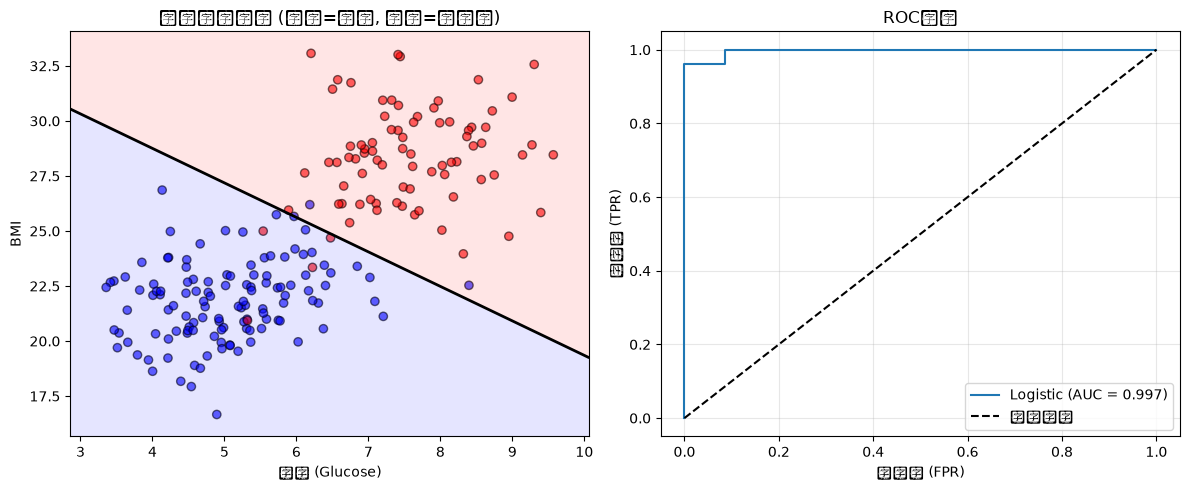

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, roc_auc_score

# 1. 读取数据并准备特征与标签
df = pd.read_csv('糖尿病风险数据.csv')
X = df[['Glucose', 'BMI']].to_numpy()
y = df['Diabetes'].astype(int).to_numpy()

# 2. 划分训练集和测试集（70% 训练，30% 测试）
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 3. 创建逻辑回归模型（使用默认参数）
model = LogisticRegression(random_state=42)
model.fit(X_train, y_train)

# 4. 输出模型参数（权重和截距）
print(f"截距 (Intercept): {model.intercept_[0]:.4f}")
print(f"系数 (Coef): Glucose={model.coef_[0][0]:.4f}, BMI={model.coef_[0][1]:.4f}")

# 5. 在测试集上进行预测（默认阈值0.5）
y_pred = model.predict(X_test)          # 类别标签（0/1）
y_pred_prob = model.predict_proba(X_test)[:, 1]  # 属于正类（糖尿病）的概率

# 6. 混淆矩阵和评估指标
cm = confusion_matrix(y_test, y_pred)
print("\n混淆矩阵：")
print(cm)

print("\n分类报告：")
print(classification_report(y_test, y_pred, target_names=['健康', '糖尿病']))

# 7. 计算ROC和AUC
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)
auc = roc_auc_score(y_test, y_pred_prob)
print(f"AUC值: {auc:.3f}")

# 8. 可视化决策边界
plt.figure(figsize=(12, 5))

# 子图1：数据散点 + 决策边界
plt.subplot(1, 2, 1)
# 绘制所有样本，按真实标签着色
colors = ['blue' if l==0 else 'red' for l in y]
plt.scatter(X[:, 0], X[:, 1], c=colors, alpha=0.6, edgecolors='k')
plt.xlabel('血糖 (Glucose)')
plt.ylabel('BMI')
plt.title('原始数据分布 (蓝色=健康, 红色=糖尿病)')

# 绘制逻辑回归的决策边界（概率=0.5的等值线）
x_min, x_max = X[:, 0].min()-0.5, X[:, 0].max()+0.5
y_min, y_max = X[:, 1].min()-1, X[:, 1].max()+1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))
Z = model.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1]
Z = Z.reshape(xx.shape)
plt.contour(xx, yy, Z, levels=[0.5], colors='black', linewidths=2)
plt.contourf(xx, yy, Z, levels=[0, 0.5, 1], alpha=0.1, colors=['blue', 'red'])

# 子图2：ROC曲线
plt.subplot(1, 2, 2)
plt.plot(fpr, tpr, label=f'Logistic (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='随机猜测')
plt.xlabel('假正率 (FPR)')
plt.ylabel('真正率 (TPR)')
plt.title('ROC曲线')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('逻辑回归结果.png', dpi=300)
plt.show()

## 6. ROC 曲线与 AUC

ROC 曲线展示模型在不同分类阈值下，真正率和假正率之间的关系。

**真正率（TPR，也就是 Recall）**：真实正类中被正确预测为正类的比例，越大越好。
$$
TPR = \frac{TP}{TP + FN}
$$

**假正率（FPR）**：真实负类中被错误预测为正类的比例，越小越好。
$$
FPR = \frac{FP}{FP + TN}
$$

ROC 以 FPR 为横轴、TPR 为纵轴。曲线越靠近左上角，分类能力越强。

**AUC（Area Under the Curve）** 是 ROC 曲线下面积，可理解为随机抽取一个正样本和一个负样本时，模型把正样本排在负样本前面的概率：

- AUC = 0.5：接近随机猜测。
- AUC 越接近 1：模型区分正负样本的能力越强。
- AUC 衡量的是排序能力，并不能直接告诉我们某个具体阈值下的 Precision 和 Recall。
- 正类极少时，PR 曲线和 PR-AUC 往往比 ROC-AUC 更能反映模型效果。

## 7. 适用场景、优缺点与建模流程

**适用场景**：疾病风险、用户流失、贷款违约、广告点击、垃圾邮件和欺诈识别等需要输出分类概率的任务。

**优点**：训练快、实现简单、输出概率、参数可解释、适合作为分类基线模型。

**局限**：基础模型只能学习线性决策边界；对异常值、强共线性和未经处理的特征尺度较敏感；复杂非线性关系通常需要特征工程或其他模型。

**推荐流程**：划分训练集和测试集 → 缺失值与异常值处理 → 特征编码与标准化 → 训练模型并调节正则化 → 在验证集选择阈值 → 使用测试集做最终评估。